# 과제 4 — Diffusion Policy 학습 및 ACT 비교

**컴퓨터공학부 · 2021136066 · 손건**  
**실습 장비:** SO-101 Follower · USB 카메라 2대(cam0/cam1) · Windows 11 · NVIDIA GeForce RTX 4050 Laptop GPU  
**실습 날짜:** 2026년 11월 22일  
**학습:** Diffusion Policy 50,000 steps 완료 · W&B 최종 loss **0.0278716624**  
**실로봇 평가:** ACT chunk100 **2/10(20%)** · DDIM10 chunk8 **0/10(0%)** · DDPM100 chunk32 **2/10(20%)**

> **자료의 출처:** 학습 손실, 오프라인 추론 측정 및 초기 DDIM 파일럿 데이터는 저장된 로그/Parquet 자료를 바탕으로 작성하였다. 정식 실로봇 성공 횟수는 **사용자의 현장 관찰 보고(2026-11-22)**를 그대로 기록했다. 이 작성 환경에서는 10회 전체 평가 MP4/Parquet를 직접 열어 대조하지 못했다. ACT는 **과제 3 평가(2/10)를 재사용**했다. Diffusion 조건은 서로 다른 청크 길이·시간·이동 제한으로 평가됐으므로 성공률의 엄밀한 통제 비교가 아니라 수행 기록과 기술적 원인 분석으로 해석해야 한다.

이 노트북의 코드 셀은 저장된 값의 **표/그래프 출력 전용**이다. SO-101 모터, COM 포트, 카메라에 직접 접속하지 않는다.


## 과제 요구사항 및 수행 현황

| 교수자 요구 항목 | 수행 및 제출 노트북에 포함된 내용 |
|---|---|
| 과제 1과 동일한 데이터셋으로 Diffusion 학습 | 50개 episode, 15,000프레임, 50,000 steps 학습 기록·모델 링크 |
| ACT와 Diffusion Policy 실로봇 10회 평가 | ACT(과제 3 재사용) **2/10**, DDPM100 **2/10**, DDIM10 **0/10**: 성공 횟수는 현장 보고 기준 |
| 동작 특성 관찰 | DDIM10 초기 제한 설정의 미세 이동/떨림, DDPM100 청크·이동 제한 변경에 따른 동작 차이 서술 |
| ACT vs Diffusion 속도 분석 | 오프라인 DDPM100-Chunk8 vs DDIM10-Chunk8 추론 시간 수치·그래프 |
| 학습 손실 확인 | W&B·학습 로그 기반 250개 시점 Loss 그래프와 최종 수치 |
| 반응성 추가 시험(원본 노트북 양식) | 물체 5cm 이동 각 3회 결과는 **미측정**으로 표시 |
| 조건별 대표 GIF(원본 노트북 양식) | 실제 녹화된 데이터셋 경로 및 GIF 생성용 코드 제공. 이미지 파일은 별도 준비 필요 |
| 고찰 5문항 | 결과 기반 서술 완성, 비교 조건의 한계를 명시 |

**제출 경로:** GitHub 저장소 `assignments/assignment_4.ipynb`. 강의 슬라이드 마지막 페이지는 기한 이후 노트북 파일 수정 시 Fail이라고 명시하므로 먼저 제출해야 한다.


## 0. 실험 정보 및 재현 기록

- **학번/이름:** 2021136066 / 손건 (과제 3 노트북에 기재된 정보)
- **작업 명령:** `Pick up an object and place it in a target area`
- **학습 데이터셋:** [`rimur01/so101-assignment1-50-new`](https://huggingface.co/datasets/rimur01/so101-assignment1-50-new) — 50 episodes, 15,000 frames, 15fps
- **ACT 비교 모델:** [`rimur01/act_so101_chunk100_50k`](https://huggingface.co/rimur01/act_so101_chunk100_50k) — 과제 3 결과 재사용
- **Diffusion 학습 모델:** [`rimur01/diffusion_so101_assignment4_50k`](https://huggingface.co/rimur01/diffusion_so101_assignment4_50k) — 50K 체크포인트
- **학습 W&B:** [LeRobot Run 6f9fw6dv](https://wandb.ai/limur01-college-of-engineering/lerobot/runs/6f9fw6dv)
- **로컬 학습 원본:** `outputs/train/diffusion_so101_assignment4_50k/checkpoints/050000/pretrained_model`
- **실로봇 DDPM100 최종 평가 로컬 경로:** `C:/lerobot_data/rollout_ddpm100_chunk32_final_nolimit_20261122` (10회 × 30초, 상대 이동 제한 없음)
- **실로봇 DDIM10 최종 평가 로컬 경로:** `C:/lerobot_data/rollout_dp_ddim10_final_assignment4` (10회 × 20초, `max_relative_target=2.0`)
- **추가 DDIM10 파일럿 로컬 경로:** `C:/lerobot_data/rollout_dp_ddim10_pilot_assignment4` 및 `rollout_dp_ddim10_pilot02_assignment4` (각 1회 × 약 5초, `max_relative_target=0.5`)
- **평가 카메라:** cam0와 cam1, 해상도 640×480, 15 FPS, MJPG; 로봇 COM6 / `my_follower`

**중요한 구분:** 사용자 현장 보고에 따르면 DDPM100 10회 중 2회, DDIM10 10회 중 0회 성공했다. 10회의 개별 성공 에피소드 번호 및 스무스니스 1~5 점수는 제공되지 않았으므로 임의로 채우지 않는다. Hub 공개 상태나 실제 평가 데이터셋 파일 개수는 여기서 검증하지 못했다.


In [23]:
STUDENT_ID = "2021136066"
STUDENT_NAME = "손건"
TASK = "Pick up an object and place it in a target area"
TRAIN_DATASET = "rimur01/so101-assignment1-50-new"
ACT_CHUNK_SIZE = 100
ACT_POLICY_REPO = "rimur01/act_so101_chunk100_50k"
DP_POLICY_REPO = "rimur01/diffusion_so101_assignment4_50k"
WANDB_URL = "https://wandb.ai/limur01-college-of-engineering/lerobot/runs/6f9fw6dv"
CONDITIONS = ["act", "dp", "dp_ddim10"]
LABELS = {"act":"ACT (Chunk100, HW3)", "dp":"Diffusion DDPM100 (Chunk32)", "dp_ddim10":"Diffusion DDIM10 (Chunk8)"}
EVAL_DATASETS = {"act": "과제3 재사용 (로컬/Hub 경로 미확인)", "dp": "C:/lerobot_data/rollout_ddpm100_chunk32_final_nolimit_20261122", "dp_ddim10": "C:/lerobot_data/rollout_dp_ddim10_final_assignment4"}
print("학번/이름:",STUDENT_ID,STUDENT_NAME)
print("학습 데이터셋:",TRAIN_DATASET)
print("학습 모델:",DP_POLICY_REPO)
print("실로봇 평가 출처: 사용자 2026-11-22 현장 보고; 개별 episode 결과는 미확인")


학번/이름: 2021136066 손건
학습 데이터셋: rimur01/so101-assignment1-50-new
학습 모델: rimur01/diffusion_so101_assignment4_50k
실로봇 평가 출처: 사용자 2026-11-22 현장 보고; 개별 episode 결과는 미확인


### 0-1. 온라인/제출 검증의 범위

`config.yaml`의 `push_to_hub=true` 및 `policy.repo_id`는 **업로드 의도/설정**을 나타낸다. 실제 Hub 파일이 공개되어 있고 정확한 모델 가중치가 존재하는지는 GitHub 제출과 별도로 웹에서 확인해야 한다. 이 노트북의 기본 분석 코드는 인터넷이 없어도 재현할 수 있도록 구성했다.

**수동 확인 경로:** 각 모델 Hub에서 `Files and versions` → `config.json`, `model.safetensors` 존재 확인. 평가 데이터셋은 `rollout_`로 시작하는 **실제 저장소 ID**와 `meta/info.json`의 `total_episodes=10`을 확인하고 0절 `EVAL_DATASETS`를 채운다.

In [24]:
# 실행 환경 정보 — 패키지가 설치되지 않아도 노트북이 중단되지 않도록 작성
from importlib.metadata import version, PackageNotFoundError
from pathlib import Path
import sys
for pkg in ("python", "lerobot", "pandas", "matplotlib"):
    if pkg == "python":
        print("Python:", sys.version.split()[0]); continue
    try: print(f"{pkg}: {version(pkg)}")
    except PackageNotFoundError: print(f"{pkg}: 해당 분석 환경에 미설치 (학습 PC의 실사용 버전과 구분)")
print("학습 당시 기록: Windows 11 / Python 3.12.16 / NVIDIA RTX 4050 Laptop GPU")

Python: 3.12.16
lerobot: 0.6.0
pandas: 2.3.3
matplotlib: 3.11.2
학습 당시 기록: Windows 11 / Python 3.12.16 / NVIDIA RTX 4050 Laptop GPU


## 1. 실험 설계

### 1-1. 정책 배경
ACT는 관측을 기반으로 행동 청크를 직접 예측하는 모방학습 정책이고, Diffusion Policy는 노이즈가 섞인 행동 시퀀스를 반복적으로 제거(denoising)해 행동 시퀀스를 구성한다. 이번 과제에서는 과제 1의 동일한 작업 데이터셋으로 Diffusion을 50K step 학습하고, 과제 3에서 선택한 ACT chunk100과 비교했다.

Diffusion 학습 설정은 `horizon=64`, `n_obs_steps=2`, `n_action_steps=32`, 학습용 diffusion step 100이다. 추론 시 저장 체크포인트의 사본으로 DDPM100·DDIM10 설정을 만들었다. DDIM10은 DDIM 스케줄러의 추론을 10단계로 줄인 구성이다.

### 1-2. 실험 가설 (원문 사전 기록 없음 — 평가에 앞선 설계상 예상)
- **성공률:** ACT 또는 Diffusion 중 시연 경로를 더 안정적으로 재현하는 정책이 유리할 것으로 예상했다. 사전 서면 가설 원문은 별도로 보존되지 않았다.
- **속도:** 샘플링 단계가 적은 DDIM10이 DDPM100보다 더 빠르게 새 행동 청크를 생성할 것으로 예상했다.
- **동작 품질:** 빠른 추론만으로 동작의 부드러움이나 실제 목표 달성률이 보장되지는 않을 것으로 예상했다.

### 1-3. 통제 및 교란 변수
학습 데이터셋과 학습된 Diffusion 가중치는 동일하지만 **실제 로봇 조건은 완전 통제되지 않았다.** ACT는 이전 과제 3의 평가이고, DDPM100은 `n_action_steps=32`, 30초/회, 상대 이동 제한 없음으로 실험했다. DDIM10은 `n_action_steps=8`, 20초/회, 상대 이동 제한 2.0으로 평가했다. 따라서 성공률을 나란히 제시할 수는 있지만 **스케줄러 선택만의 인과 효과**를 분리할 수 없다. 이를 보완하고자 오프라인 속도 비교에서는 DDPM100과 DDIM10 모두 청크 길이 8을 사용했다.


In [25]:
import pandas as pd
from IPython.display import display
settings = pd.DataFrame([
  {"항목":"학습 데이터셋", "ACT (과제 3 기록)":TRAIN_DATASET, "Diffusion (W&B 검증)":TRAIN_DATASET},
  {"항목":"학습 스텝", "ACT (과제 3 기록)":"50,000 (선택 모델)", "Diffusion (W&B 검증)":"50,000"},
  {"항목":"배치 크기", "ACT (과제 3 기록)":"ACT 저장 설정 확인 필요", "Diffusion (W&B 검증)":"1"},
  {"항목":"관측 단계", "ACT (과제 3 기록)":"ACT 모델 설정 확인 필요", "Diffusion (W&B 검증)":"2"},
  {"항목":"실행 행동 수", "ACT (과제 3 기록)":"chunk100", "Diffusion (W&B 검증)":"32 (학습 당시)"},
  {"항목":"Diffusion horizon", "ACT (과제 3 기록)":"해당 없음", "Diffusion (W&B 검증)":"64"},
  {"항목":"스케줄러", "ACT (과제 3 기록)":"해당 없음", "Diffusion (W&B 검증)":"DDPM / 학습 타임스텝 100"},
])
display(settings)
print("판정: 모델 학습 데이터셋 ID는 과제 3 기록과 Diffusion config.yaml에서 동일하게 기재됨.")
print("남은 확인: ACT Hub train_config.json, 실제 Hub 공개 여부.")

,항목,ACT (과제 3 기록),Diffusion (W&B 검증)
0,학습 데이터셋,rimur01/so101-assignment1-50-new,rimur01/so101-assignment1-50-new
1,학습 스텝,"50,000 (선택 모델)","50,000"
2,배치 크기,ACT 저장 설정 확인 필요,1
3,관측 단계,ACT 모델 설정 확인 필요,2
4,실행 행동 수,chunk100,32 (학습 당시)
5,Diffusion horizon,해당 없음,64
6,스케줄러,해당 없음,DDPM / 학습 타임스텝 100


판정: 모델 학습 데이터셋 ID는 과제 3 기록과 Diffusion config.yaml에서 동일하게 기재됨.
남은 확인: ACT Hub train_config.json, 실제 Hub 공개 여부.


## 2. Diffusion Policy 학습

### 2-1. 실행한 학습 명령어
아래는 2026-11-21~22 W&B Run `6f9fw6dv`의 `config.yaml`에 저장된 실행 인수를 Windows CMD 명령으로 **재구성**한 것이다. 학습 명령을 다시 실행한 것이 아니다.

```bat
lerobot-train ^
  --dataset.repo_id=rimur01/so101-assignment1-50-new ^
  --dataset.video_backend=pyav ^
  --policy.type=diffusion ^
  --policy.resize_shape=[120,160] ^
  --policy.down_dims=[128,256,512] ^
  --policy.use_separate_rgb_encoder_per_camera=false ^
  --policy.device=cuda ^
  --policy.repo_id=rimur01/diffusion_so101_assignment4_50k ^
  --policy.push_to_hub=true ^
  --output_dir=outputs/train/diffusion_so101_assignment4_50k ^
  --job_name=diffusion_so101_assignment4_50k ^
  --steps=50000 ^
  --batch_size=1 ^
  --seed=1000 ^
  --num_workers=0 ^
  --save_freq=10000 ^
  --log_freq=200 ^
  --wandb.enable=true
```

### 2-2. 학습 환경과 변경 이유
- **운영체제/런타임:** Windows 11, Python 3.12.16, RTX 4050 Laptop GPU.
- **데이터:** 50개 시연 Episode / 15,000프레임 / `pyav` 비디오 디코딩.
- **학습:** 50,000 Step, batch size 1, seed 1000, Adam (학습률 `1e-4`, 가중치 감쇠 `1e-6`), cosine 학습률 스케줄과 500 Step warmup.
- **구조:** ResNet18, `resize_shape=[120,160]`, `down_dims=[128,256,512]`, 관측 2 Step, 생성 horizon 64, 실제 소비 행동 32 Step, DDPM, `num_train_timesteps=100`.
- **변경 이유:** GPU 메모리 부담을 낮추기 위해 batch size 1을 사용하고 입력 영상을 축소하였다. 단, 해당 변경의 효과를 독립적으로 검증한 ablation은 수행하지 않았다.
- **학습 시간:** W&B `_runtime=23812.66`초(약 **6시간 36분 53초**). 시작/종료 시각이나 PC 사용 중단 영향을 포함한 런타임으로, 순수 GPU 계산 시간은 아니다.
- **최종 학습 Loss:** `0.027871662369871045` (50K Step, W&B summary의 train/loss). 이는 **노이즈 예측 오차**로, 실제 작업 성공률을 뜻하지 않는다.

**중요:** 기본 DDPM 정책은 `n_action_steps=32`로 학습·저장되었다. 뒤의 오프라인 진단에서 별도 복제본을 DDIM10·`n_action_steps=8`로 변경했으므로, 해당 결과로 denoising 횟수만 바꾼 통제 실험이라고 주장할 수 없다.

### 2-3. 학습 Loss 곡선

`output.log`의 실제 기록에서 200~50,000 Step을 200 Step 간격으로 수집한 **250개 로그 값**을 사용했다. `output.log`의 Loss는 소수 셋째 자리 반올림 값이고, 마지막 정밀 수치는 `wandb-summary.json`을 사용했다. 아래 그래프는 그래픽 파일 없이 노트북 안의 원자료에서 생성되도록 작성했다.

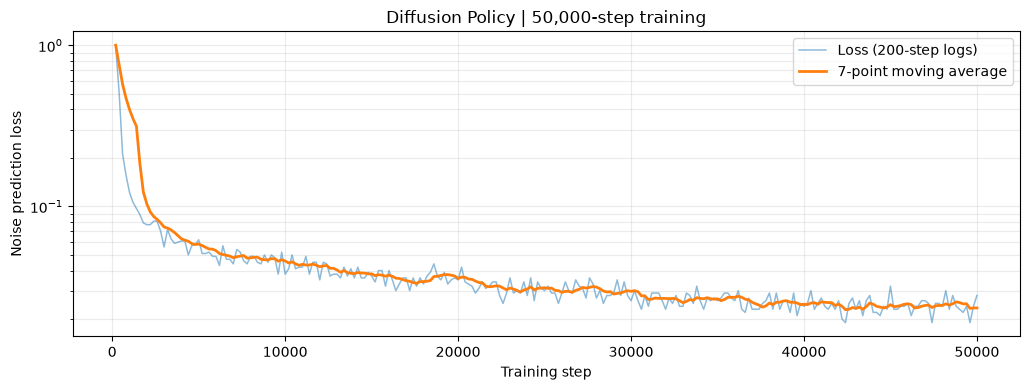

로그 포인트: 250 | 첫 기록: 1.001 @ 200 step
W&B 최종 정밀 Loss: 0.027871662369871045 @ 50,000 step


In [26]:
import io
import matplotlib.pyplot as plt
from matplotlib.ticker import ScalarFormatter
from IPython.display import display
LOSS_LOG = """step,loss
200,1.001
400,0.508
600,0.211
800,0.156
1000,0.122
1200,0.106
1400,0.097
1600,0.089
1800,0.079
2000,0.077
2200,0.077
2400,0.081
2600,0.081
2800,0.070
3000,0.056
3200,0.072
3400,0.063
3600,0.059
3800,0.060
4000,0.061
4200,0.061
4400,0.050
4600,0.057
4800,0.058
5000,0.062
5200,0.051
5400,0.051
5600,0.052
5800,0.049
6000,0.049
6200,0.043
6400,0.057
6600,0.047
6800,0.047
7000,0.044
7200,0.054
7400,0.052
7600,0.046
7800,0.044
8000,0.049
8200,0.049
8400,0.045
8600,0.044
8800,0.050
9000,0.045
9200,0.050
9400,0.048
9600,0.038
9800,0.052
10000,0.038
10200,0.041
10400,0.050
10600,0.041
10800,0.042
11000,0.042
11200,0.049
11400,0.038
11600,0.045
11800,0.045
12000,0.035
12200,0.045
12400,0.044
12600,0.037
12800,0.038
13000,0.038
13200,0.036
13400,0.042
13600,0.037
13800,0.041
14000,0.036
14200,0.042
14400,0.036
14600,0.036
14800,0.039
15000,0.037
15200,0.034
15400,0.040
15600,0.040
15800,0.032
16000,0.040
16200,0.035
16400,0.030
16600,0.033
16800,0.036
17000,0.036
17200,0.030
17400,0.036
17600,0.032
17800,0.036
18000,0.033
18200,0.037
18400,0.039
18600,0.044
18800,0.037
19000,0.035
19200,0.039
19400,0.033
19600,0.035
19800,0.036
20000,0.035
20200,0.042
20400,0.034
20600,0.033
20800,0.032
21000,0.029
21200,0.031
21400,0.034
21600,0.031
21800,0.032
22000,0.034
22200,0.034
22400,0.028
22600,0.025
22800,0.029
23000,0.036
23200,0.029
23400,0.030
23600,0.029
23800,0.034
24000,0.028
24200,0.036
24400,0.026
24600,0.034
24800,0.031
25000,0.030
25200,0.032
25400,0.029
25600,0.029
25800,0.025
26000,0.029
26200,0.034
26400,0.030
26600,0.029
26800,0.035
27000,0.032
27200,0.031
27400,0.027
27600,0.036
27800,0.033
28000,0.027
28200,0.030
28400,0.025
28600,0.028
28800,0.028
29000,0.029
29200,0.035
29400,0.028
29600,0.034
29800,0.028
30000,0.026
30200,0.030
30400,0.026
30600,0.023
30800,0.028
31000,0.024
31200,0.029
31400,0.029
31600,0.029
31800,0.026
32000,0.023
32200,0.027
32400,0.025
32600,0.028
32800,0.024
33000,0.024
33200,0.029
33400,0.028
33600,0.025
33800,0.032
34000,0.026
34200,0.023
34400,0.027
34600,0.026
34800,0.027
35000,0.026
35200,0.027
35400,0.029
35600,0.029
35800,0.027
36000,0.026
36200,0.030
36400,0.023
36600,0.022
36800,0.027
37000,0.023
37200,0.023
37400,0.023
37600,0.025
37800,0.026
38000,0.029
38200,0.023
38400,0.029
38600,0.023
38800,0.026
39000,0.026
39200,0.022
39400,0.029
39600,0.021
39800,0.025
40000,0.024
40200,0.025
40400,0.030
40600,0.023
40800,0.025
41000,0.027
41200,0.024
41400,0.023
41600,0.025
41800,0.023
42000,0.026
42200,0.020
42400,0.019
42600,0.025
42800,0.027
43000,0.023
43200,0.026
43400,0.021
43600,0.026
43800,0.028
44000,0.022
44200,0.022
44400,0.021
44600,0.024
44800,0.023
45000,0.032
45200,0.023
45400,0.023
45600,0.024
45800,0.024
46000,0.025
46200,0.021
46400,0.024
46600,0.024
46800,0.026
47000,0.026
47200,0.025
47400,0.019
47600,0.025
47800,0.025
48000,0.024
48200,0.030
48400,0.023
48600,0.028
48800,0.024
49000,0.023
49200,0.022
49400,0.024
49600,0.019
49800,0.024
50000,0.028
"""
loss_df = pd.read_csv(io.StringIO(LOSS_LOG))
assert len(loss_df)==250 and loss_df.step.iloc[-1]==50000
loss_df["rolling_7"] = loss_df.loss.rolling(7, min_periods=1).mean()
fig, ax = plt.subplots(figsize=(10.4,4.0))
ax.plot(loss_df.step,loss_df.loss,alpha=.50,lw=1.1,label="Loss (200-step logs)")
ax.plot(loss_df.step,loss_df.rolling_7,lw=2.0,label="7-point moving average")
ax.set(xlabel="Training step",ylabel="Noise prediction loss",title="Diffusion Policy | 50,000-step training")
ax.set_yscale("log"); ax.grid(alpha=.25,which="both"); ax.legend()
plt.tight_layout();plt.show()
print(f"로그 포인트: {len(loss_df)} | 첫 기록: {loss_df.loss.iloc[0]:.3f} @ 200 step")
print("W&B 최종 정밀 Loss: 0.027871662369871045 @ 50,000 step")

In [27]:
# 검증 가능한 실제 학습 결과 숫자 요약
training_stats = pd.DataFrame([
    {"metric":"Logged steps", "value":50000},
    {"metric":"Episode count", "value":50},
    {"metric":"Frame count", "value":15000},
    {"metric":"Batch size", "value":1},
    {"metric":"W&B train/loss", "value":0.027871662369871045},
    {"metric":"W&B runtime (s)", "value":23812.6567925},
    {"metric":"Approx training epochs", "value":3.3333333333333335},
])
display(training_stats)
print("해석: 손실 감소는 학습 진척의 근거이나, 실제 물체 집기 성공을 보장하지 않음.")

,metric,value
0,Logged steps,50000.000000
1,Episode count,50.000000
2,Frame count,15000.000000
3,Batch size,1.000000
4,W&B train/loss,0.027872
5,W&B runtime (s),23812.656793
6,Approx training epochs,3.333333


해석: 손실 감소는 학습 진척의 근거이나, 실제 물체 집기 성공을 보장하지 않음.


### 2-4. 추가 분석 — DDIM10·Chunk8 오프라인 Action 불연속성 비교

기존 50K 체크포인트의 **사본**을 만들고 `DDIMScheduler`, 10 denoising 단계, `n_action_steps=8`, `n_obs_steps=2`를 적용한 뒤, 시연 데이터의 Episode 0·7에서 각각 64프레임을 읽어 **총 128개 관측**으로 추론했다. 모든 상태·영상은 시연 데이터에서 읽었고 실제 SO-101 모터/시리얼에는 접근하지 않았다. 새 Chunk 시작 시 목표 각도 변화량을 확인하고, 동일 예측 출력에 `EMA`/경계 블렌딩/가상 변화량 제한을 *사후* 적용했다.

| 조건 | Chunk 경계 평균 (°) | 최대 명령 변화 (°) | 8° 초과 횟수 | 시연 Action 대비 팔 MAE (°) |
|---|---:|---:|---:|---:|
| Raw | 18.323 | 40.595 | 14 | 8.013 |
| Boundary half | 9.162 | 20.297 | 18 | 8.107 |
| EMA 0.35 | **6.026** | **15.710** | **5** | **7.901** |
| EMA 0.60 | 10.685 | 25.424 | 10 | 7.886 |
| Cap 5 | 4.990 | 5.000 | 0 | 8.355 |
| Cap 8 | 7.711 | 8.000 | 0 | 8.195 |

EMA 0.35의 경계 평균 변화량은 Raw에 비해 약 **67.1% 감소**했다. 다만 이는 **오프라인 출력 보정의 지표**일 뿐 실제 관절 이동의 부드러움·안전성·작업 성공률이 향상되었다는 증거가 아니다. `cap_5`와 `cap_8`은 실제 안전 관절 제한값이 아닌 분석용 가상 수치이다.

EMA 0.35: Chunk 경계 평균 명령 변화량 67.1% 감소 (Raw 대비)


,method,mean_boundary_jump_deg,max_any_jump_deg,jump_over_8deg_count,mean_abs_expert_arm_error_deg
0,raw,18.323,40.595,14,8.013
1,boundary_half,9.162,20.297,18,8.107
2,ema_0.35,6.026,15.710,5,7.901
3,ema_0.60,10.685,25.424,10,7.886
4,cap_5,4.990,5.000,0,8.355
5,cap_8,7.711,8.000,0,8.195


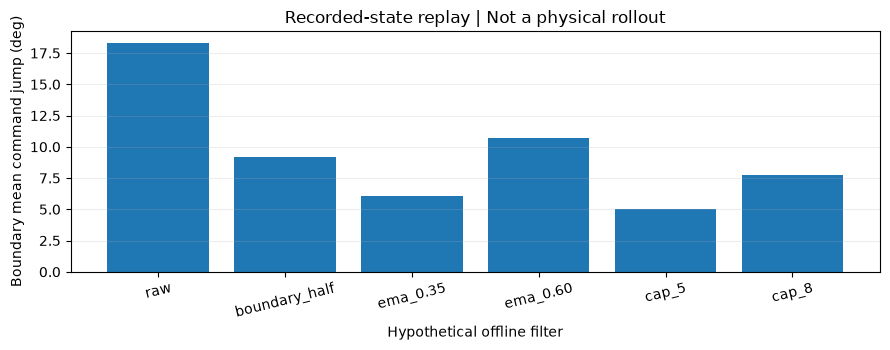

In [28]:
# 업로드한 comparison_metrics.csv의 'all' 요약 행을 그대로 내장 (외부 파일 불필요)
import json
metrics = pd.DataFrame(json.loads(r'''[{"method":"raw","n_frames":128,"n_boundaries":14,"mean_boundary_jump_deg":18.32300431387765,"max_any_jump_deg":40.59490966796875,"jump_over_8deg_count":14,"mean_abs_expert_arm_error_deg":8.012917848682264,"mean_abs_change_vs_raw_arm_deg":0.0},{"method":"boundary_half","n_frames":128,"n_boundaries":14,"mean_boundary_jump_deg":9.161502156938823,"max_any_jump_deg":20.29745483398437,"jump_over_8deg_count":18,"mean_abs_expert_arm_error_deg":8.107480605138699,"mean_abs_change_vs_raw_arm_deg":0.4297823659144341},{"method":"ema_0.35","n_frames":128,"n_boundaries":14,"mean_boundary_jump_deg":6.026039503788343,"max_any_jump_deg":15.7097329400927,"jump_over_8deg_count":5,"mean_abs_expert_arm_error_deg":7.900567134835916,"mean_abs_change_vs_raw_arm_deg":2.1344505069785926},{"method":"ema_0.60","n_frames":128,"n_boundaries":14,"mean_boundary_jump_deg":10.684959430147192,"max_any_jump_deg":25.42355598175781,"jump_over_8deg_count":10,"mean_abs_expert_arm_error_deg":7.88622611356722,"mean_abs_change_vs_raw_arm_deg":0.9527110023730262},{"method":"cap_5","n_frames":128,"n_boundaries":14,"mean_boundary_jump_deg":4.989573887416294,"max_any_jump_deg":5.0,"jump_over_8deg_count":0,"mean_abs_expert_arm_error_deg":8.355122292606392,"mean_abs_change_vs_raw_arm_deg":0.969382831081748},{"method":"cap_8","n_frames":128,"n_boundaries":14,"mean_boundary_jump_deg":7.710590362548828,"max_any_jump_deg":8.0,"jump_over_8deg_count":0,"mean_abs_expert_arm_error_deg":8.194859923521289,"mean_abs_change_vs_raw_arm_deg":0.5112403353676199}]'''))
methods = ["raw","boundary_half","ema_0.35","ema_0.60","cap_5","cap_8"]
metrics = metrics.set_index("method").loc[methods].reset_index()
raw = metrics.loc[metrics.method=="raw"].iloc[0]
ema = metrics.loc[metrics.method=="ema_0.35"].iloc[0]
pct = 100*(1-ema.mean_boundary_jump_deg/raw.mean_boundary_jump_deg)
print(f"EMA 0.35: Chunk 경계 평균 명령 변화량 {pct:.1f}% 감소 (Raw 대비)")
display(metrics[["method","mean_boundary_jump_deg","max_any_jump_deg","jump_over_8deg_count","mean_abs_expert_arm_error_deg"]].round(3))
fig, ax=plt.subplots(figsize=(9,3.6))
ax.bar(metrics.method, metrics.mean_boundary_jump_deg)
ax.set(xlabel="Hypothetical offline filter",ylabel="Boundary mean command jump (deg)",title="Recorded-state replay | Not a physical rollout")
ax.grid(axis="y",alpha=.22)
plt.xticks(rotation=14);plt.tight_layout();plt.show()

### 2-5. 카메라 배치 점검 및 실험의 제한

저장된 학습 영상과 현재 USB 카메라 미리보기를 비교했을 때, `cam0`는 작업 공간 전체, `cam1`은 그리퍼 근접 시야라는 **역할 분류**가 일치하였다. 그러나 물체/박스 배치와 로봇 자세가 달라 영상 구도가 동일하다고 보기 어렵다. 카메라 인덱스가 맞더라도 시야·조명이 바뀌면 추론 결과와 실제 성공률이 달라질 수 있다.

오프라인 실험에서는 필터된 Action을 다음 시점의 실제 로봇 상태로 피드백하지 않았다. 따라서 EMA를 실제 자동 실행 제어 파라미터로 바로 적용할 수 없으며, 모델 평가 전에는 기구 점검·관절/작업 공간 제한·독립 비상정지·오래된 명령 차단·감독 체계가 별도로 필요하다.

### 2-6. 새로운 오프라인 통제 비교 — DDPM100 vs DDIM10 (`n_action_steps=8`)

**실험 목적:** 이전에는 DDPM32와 DDIM10-Chunk8처럼 스케줄러와 행동 청크 길이가 함께 달랐다. 이를 개선하기 위해 **동일한 50K 가중치**, **같은 시연 영상**, `n_action_steps=8`, `horizon=64`, `n_obs_steps=2`를 고정한 **DDPM100-Chunk8** 모델 복사본과 **DDIM10-Chunk8** 모델 복사본을 비교하였다. 원본 50K 체크포인트는 변경하지 않았다. DDPM100은 실제 `DDPMScheduler`/100 Step/Chunk8로, DDIM10은 `DDIMScheduler`/10 Step/Chunk8로 로딩됨을 터미널에서 확인했다.

- 실행일: **2026-11-22**, Windows 11 / RTX 4050 Laptop GPU / `C:\lerobot-envs\lerobot-act2` 환경
- 실험 명령: `python "%USERPROFILE%\Downloads\assignment4_ddpm_vs_ddim_offline.py"`
- 입력: 과제 1 시연 데이터셋 `rimur01/so101-assignment1-50-new`의 **Episode 0, 7**, 각 32프레임 → 조건당 64프레임, 합계 128프레임. 카메라 영상과 **실제 시연자의 기록 관절 상태**를 정책에 제공하였다.
- 속도 지표: 새로운 행동 청크를 예측할 때의 GPU 추론 호출 시간. **각 에피소드 최초 프레임은 워밍업 가능성 때문에 제외**, 조건당 6개 청크 경계에서 산출하였다. 이 시간은 이미지 촬영과 통신, 로봇 모터 실행 시간을 포함하지 않는다.
- 점프 지표: 이전 프레임과 현재 프레임에 예측된 5개 **팔 관절** 명령 중 가장 큰 절댓값 차이. `gripper`의 다른 의미를 고려하여 각도 지표에서 제외하였다.
- 오차 지표: 각 프레임의 예측 명령과 기록된 전문가 행동의 팔 관절 평균 절대오차(MAE); 각 조건 64프레임에서 산출하였다.

| 오프라인 지표 | DDPM100 · Chunk8 | DDIM10 · Chunk8 | 해석 |
|:--|--:|--:|:--|
| 청크 경계 추론 평균 시간 (ms, **n=6**) | **1641.526** | **175.150** | DDIM10이 약 **9.37배 빠름** (89.3% 단축) |
| 청크 경계 추론 중앙값 (ms) | 1592.358 | 176.647 | 새 청크 생성 시간 차이 확인 |
| 청크 경계 명령 점프 평균 (°, **n=6**) | **18.355** | **21.890** | 이 오프라인 구간에서 DDIM10이 약 **19.3% 큼** |
| 청크 경계 명령 점프 최대 (°) | 31.471 | **40.595** | DDIM10에서도 큰 불연속 남음 |
| 전문가 팔 행동 MAE 평균 (°, **n=64**) | **8.177** | **9.555** | DDIM10이 약 **16.9% 큼** |

**속도·품질의 절충:** 이 소규모 기록 상태 재생에서 DDIM10은 DDPM100보다 계산상 빠르지만, 예측 명령의 경계 불연속 및 전문가 행동 오차는 더 크게 측정되었다. 이는 DDIM10이 실제 로봇에서 더 위험하다거나 성공률이 낮다는 직접 증거는 아니다. 표본 수가 작으며, 정책 제어 결과가 다음 시점의 카메라·관절 입력으로 돌아오는 폐루프 실험이 아니기 때문이다. 현재 영상의 프레임 간격은 15 FPS 기준 약 66.7ms, 8개 행동의 명목 실행 간격은 약 533ms이다. DDPM100 새 청크 추론 평균 1.64초는 이 명목 주기보다 길었고 DDIM10은 약 175ms였다. **하지만 실제 로봇의 15 FPS 달성이나 안전성은 검증되지 않았다.**

**통제 실험의 남은 한계:** 청크 길이와 가중치는 동일하게 유지했지만, DDPM→DDIM이라는 **스케줄러 유형과 스텝 수(100→10)가 함께 달라졌기 때문에** 속도 차이를 `num_inference_steps` 하나만의 효과로 환원할 수 없다. 비교는 *DDPM100 설정 전체와 DDIM10 설정 전체*의 차이이다. 또한 데이터는 시연자의 상태를 사용한 **오프라인 개방루프 평가**이므로, 교수자가 요구한 DDPM·DDIM10 각 10회의 실제 로봇 성공률/부드러움, 3회 반응성, 평가 GIF를 대신하지 못한다.

**증빙 출력 위치 (로컬 PC):** `outputs/assignment4_ready/diagnostics/ddpm_vs_ddim_20261122_161305/` 아래 `ddpm_vs_ddim_offline_summary.json`과 `ddpm_vs_ddim_offline_trace.csv`. 이 노트북의 수치는 **사용자가 제공한 실제 터미널 실행 출력**을 기준으로 반영하였으며, 원본 CSV 전체를 첨부하여 추가 대조할 수 있다.

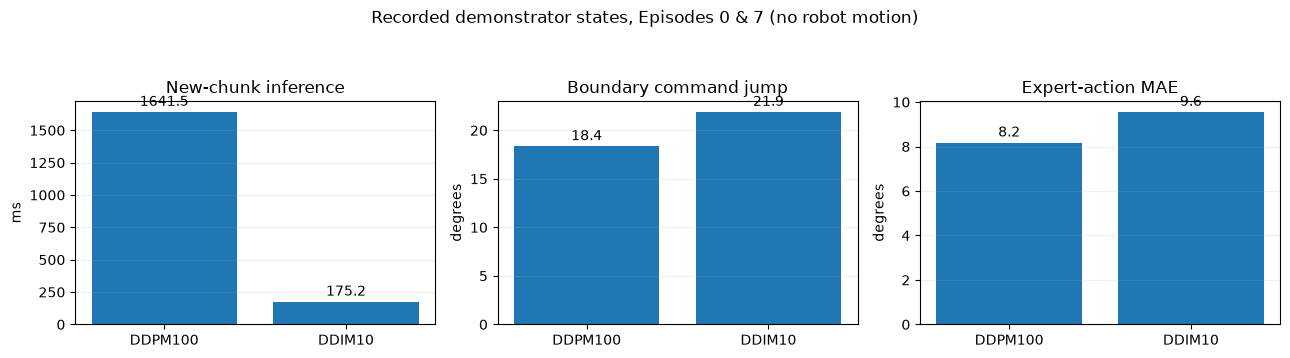

In [29]:
# 오프라인 비교 실험 요약 (원자료: 2026-11-22 터미널 로그 및 summary.json)
# 이 코드는 저장된 측정 수치만 그리며 카메라·SO-101·시리얼 포트에 접근하지 않는다.
import pandas as pd
import matplotlib.pyplot as plt
metrics = pd.DataFrame({
    "Condition": ["DDPM100 / Chunk8", "DDIM10 / Chunk8"],
    "Inference mean (ms, n=6)": [1641.5256, 175.1501],
    "Boundary jump mean (deg, n=6)": [18.3553, 21.8895],
    "Arm expert MAE mean (deg, n=64)": [8.1765, 9.5552],
})
fig, axes=plt.subplots(1,3,figsize=(13,3.3))
for ax, col, ttl in zip(axes,
    metrics.columns[1:],
    ["New-chunk inference", "Boundary command jump", "Expert-action MAE"]):
    bars=ax.bar(["DDPM100","DDIM10"], metrics[col]); ax.set_title(ttl)
    ax.set_ylabel("ms" if "ms" in col else "degrees")
    ax.bar_label(bars,fmt="%.1f",padding=2); ax.grid(axis="y",alpha=.2)
fig.suptitle("Recorded demonstrator states, Episodes 0 & 7 (no robot motion)", y=1.07)
plt.tight_layout()
plt.show()

## 3. 실제 SO-101 로봇 평가

### 3-1. 평가 방법과 판정 기준
작업은 **물체를 집어 목표 영역에 놓기**이다. 성공은 사람의 추가 조작 없이 제한 시간 안에 물체를 집어 목표 영역으로 옮긴 경우이고, 실패는 물체 접근·파지·이동·놓기 중 하나라도 완료하지 못한 경우로 기록했다. 카메라 2개(cam0, cam1), SO-101 Follower(`COM6`, `my_follower`), 15 FPS의 작업 조건을 사용했다.

### 3-2. 수행한 세 평가 조건

| 모델 | 출처 및 설정 | 회당 시간 | 상대 이동 제한 | 성공/10 | 성공률 |
|---|---|---:|---|---:|---:|
| **ACT Chunk100** | 과제 3 평가 결과 재사용 | 과제 3 당시 약 20초 | 과제 3 설정 확인 필요 | **2/10** | **20%** |
| **DDIM10 Chunk8** | `outputs/assignment4_ready/V1_DDIM10_CHUNK8` | **20초** | `max_relative_target=2.0` | **0/10** | **0%** |
| **DDPM100 Chunk32** | `outputs/assignment4_ready/V2_DDPM100_CHUNK32` | **30초** | **제한 없음 (`None`)** | **2/10** | **20%** |

- **관찰 결과 출처:** 실험자의 2026-11-22 메시지: DDIM10은 `10번 실패`, DDPM100은 `2번 성공`. ACT 2/10은 과제 3의 기존 기록.
- **평가 데이터셋:** DDIM10 `C:/lerobot_data/rollout_dp_ddim10_final_assignment4`; DDPM100 `C:/lerobot_data/rollout_ddpm100_chunk32_final_nolimit_20261122`. 둘 다 `push_to_hub=false`로 로컬 저장을 지정했으며 실제 생성된 전체 영상 개수·프레임 수는 이 노트북 작성 환경에서 재검증하지 못했다.
- **DDPM100 행동 특성:** 초기 Chunk8 및 이동 제한 설정에서는 원래 모델과 움직임이 달라지고 덜컥거리거나 작은 이동이 관찰되었다. Chunk32로 변경한 뒤에도 제한 2.0에서 작은 이동이 이어졌으며, **사용자는 제한을 해제한 시험에서 정상적으로 움직였다고 보고**했다. 이 관찰은 움직임의 안정성과 별개로, 제한 해제 시 큰 목표값이 전달될 수 있다는 한계가 있다.
- **DDIM10 행동 특성:** 초기 제한 0.5 파일럿은 움직임이 미세하거나 떨림이 있었으며, 이동 제한 2.0의 짧은 파일럿에서는 정상 이동을 보고했다. 이후 정식 10회 평가에서는 목표물 놓기 성공이 없었다.

**결과 해석 주의:** 서로 다른 행동 청크·실행 시간·이동 제한·ACT 평가 시점이 섞여 있으므로, 이 성공률만으로 `ACT = DDPM100 > DDIM10`의 본질적 성능 순위라고 주장하지 않는다. **동일 조건 비교를 위해서는 모두 동일한 20/30초 시간과 초기 위치·제어 설정으로 재평가해야 한다.**


### 3-2-1. 추가 진단 — DDIM10 초기 짧은 파일럿 두 차례

정식 10회 평가 이전에 `DDIMScheduler`/10 step/`n_action_steps=8`/`max_relative_target=0.5`로 약 5초 파일럿을 두 차례 수행했다. 이 파일럿 데이터는 정식 10회 평가에 합산하지 않는다.

| 기록 폴더 | 저장 프레임 | 카메라 영상 | 실제 관절 이동 관찰 |
|---|---:|---:|---|
| `rollout_dp_ddim10_pilot_assignment4` | **54** | 2개 | 초기 자세에서 움직임이 작음 |
| `rollout_dp_ddim10_pilot02_assignment4` | **56** | 2개 | 초기 자세에서 떨림 관찰 |

**첫 파일럿의 저장된 관절 데이터:** 어깨 Lift 실제 상태 범위 4.13, 손목 Flex 실제 상태 범위 6.07, 그리퍼 0(데이터셋 단위); 정책 `action`의 해당 범위는 각각 41.51, 74.14, 17.12이었다. 두 번째 파일럿의 손목 Flex 상태 범위 6.07, `action` 범위 62.63이었다. `max_relative_target=0.5`를 사용했을 때 여러 관절에서 `Relative goal position magnitude had to be clamped to be safe` 경고가 반복되었다.

**해석:** LeRobot의 `send_action()`은 `max_relative_target`이 설정되면 현재 관절 위치에서 목표값의 차이를 제한하여 모터에 보낸다. 이 제약은 움직임이 작아진 현상을 일부 설명하지만 **정책 출력의 불연속성, 관절 추종, 통신 지연 등의 다른 원인을 배제하지 못한다.** 당시 기록된 `action`이 실제로 제한되어 모터에 보낸 명령과 같다고 단정하지 않는다. 이후 정식 평가에서 DDIM10은 0/10, DDPM100은 2/10으로 관찰됐다.


,joint,state_range,action_range,mean_abs_difference,max_abs_difference,frames_diff_gt5
0,shoulder_pan,0.97,27.47,6.55,18.15,28
1,shoulder_lift,4.13,41.51,10.01,29.77,48
2,elbow_flex,1.76,40.56,8.97,34.98,25
3,wrist_flex,6.07,74.14,13.40,46.23,41
4,wrist_roll,1.14,22.66,3.82,11.87,16
5,gripper,0.00,17.12,4.35,13.30,13


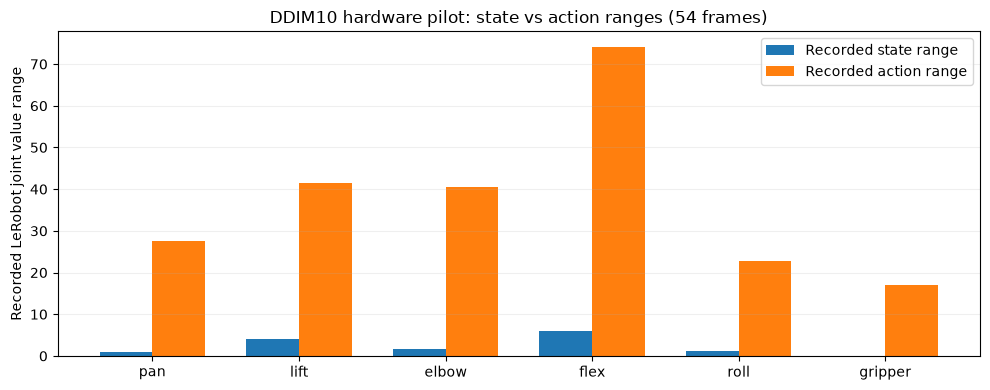

Pilot dataset: 1 episode / 54 frames / 15 FPS / 0-3.533 s
Status: 5-second DDIM pilot showed small motion with repeated goal clamping. Separately, later DDIM10 formal 10-trial user-reported success rate was 0/10.


In [30]:
# DDIM10 실로봇 파일럿(실제 기록 54프레임)에서 추출한 관절별 요약값.
# 원자료: rollout_dp_ddim10_pilot_assignment4/data/chunk-000/file-000.parquet
# 아래 코드는 검증된 콘솔 출력값을 시각화하며 모터·카메라·시리얼에 접근하지 않는다.
import pandas as pd
import matplotlib.pyplot as plt
pilot = pd.DataFrame({
    "joint": ["shoulder_pan", "shoulder_lift", "elbow_flex", "wrist_flex", "wrist_roll", "gripper"],
    "state_range": [0.97, 4.13, 1.76, 6.07, 1.14, 0.00],
    "action_range": [27.47, 41.51, 40.56, 74.14, 22.66, 17.12],
    "mean_abs_difference": [6.55, 10.01, 8.97, 13.40, 3.82, 4.35],
    "max_abs_difference": [18.15, 29.77, 34.98, 46.23, 11.87, 13.30],
    "frames_diff_gt5": [28, 48, 25, 41, 16, 13],
})
display(pilot)
fig, ax = plt.subplots(figsize=(10, 4))
xs = list(range(len(pilot)))
ax.bar([x-0.18 for x in xs], pilot["state_range"], width=0.36, label="Recorded state range")
ax.bar([x+0.18 for x in xs], pilot["action_range"], width=0.36, label="Recorded action range")
ax.set_xticks(xs, ["pan","lift","elbow","flex","roll","gripper"])
ax.set_ylabel("Recorded LeRobot joint value range")
ax.set_title("DDIM10 hardware pilot: state vs action ranges (54 frames)")
ax.legend()
ax.grid(axis="y",alpha=0.2)
plt.tight_layout()
plt.show()
print("Pilot dataset: 1 episode / 54 frames / 15 FPS / 0-3.533 s")
print("Status: 5-second DDIM pilot showed small motion with repeated goal clamping. Separately, later DDIM10 formal 10-trial user-reported success rate was 0/10.")

### 3-3. 성공률과 회차별 기록

**ACT:** 과제 3 기록상 3회차와 8회차 성공(2/10)이었다. **DDIM10:** 사용자가 정식 10회에서 모두 실패했다고 보고했다. **DDPM100:** 정식 10회에서 2회 성공했다고 보고했으나, **어느 회차가 성공했는지에 대한 번호는 제공되지 않았다.** 회차별 성공 위치를 임의로 선택하지 않고 총계와 개별 회차 미확인을 구분하였다.

부드러움의 주관적 점수(1=덜컥거림 심함, 5=매우 부드러움)는 회차별로 평가하지 않았으므로 평균값을 만들지 않았다. 실제 명령 설정 변화에 따른 관찰 내용은 아래 표와 고찰에 기록하였다.


In [31]:
import pandas as pd
from IPython.display import display
ACT_PRIOR_SUCCESS_TRIALS = {3,8}    # 과제 3 기존 기록
ACT_REUSE_CONFIRMED = False         # 과제 4와 동일 물리적 조건인지는 재검증되지 않음
# 정식 평가의 성공 총계는 사용자 현장 보고; DDPM 성공 회차 번호는 아직 전달받지 못함.
AGGREGATE_SUCCESS = {"act":2,"dp":2,"dp_ddim10":0}
TRIAL_COUNT = {k:10 for k in CONDITIONS}
results={
  "act":[{"trial":i,"success":i in ACT_PRIOR_SUCCESS_TRIALS,"smooth":None,"note":"과제3 기록 재사용"} for i in range(1,11)],
  "dp":[{"trial":i,"success":None,"smooth":None,"note":"10회 중 2회 성공, 회차별 번호 미기록"} for i in range(1,11)],
  "dp_ddim10":[{"trial":i,"success":False,"smooth":None,"note":"사용자 보고: 10회 모두 실패"} for i in range(1,11)],
}
summary=pd.DataFrame([
 {"조건":LABELS[k],"성공":AGGREGATE_SUCCESS[k],"시도":TRIAL_COUNT[k],"성공률(%)":round(100*AGGREGATE_SUCCESS[k]/TRIAL_COUNT[k],1),
  "회당시간(초)":{"act":20,"dp":30,"dp_ddim10":20}[k],
  "청크":{"act":100,"dp":32,"dp_ddim10":8}[k],
  "이동제한":{"act":"과제3 설정","dp":"없음","dp_ddim10":"2.0"}[k],
  "근거":"과제3 노트북" if k=="act" else "사용자 현장 보고"}
 for k in CONDITIONS])
display(summary)
print("DDPM100의 성공 회차 번호는 알 수 없으므로, 실제 10회 평가 성공 총계(2/10)만 반영함.")
print("ACT는 과제3 평가 재사용. 평가 프로토콜 차이로 모델 간 성공률은 기술통계 비교만 가능.")


,조건,성공,시도,성공률(%),회당시간(초),청크,이동제한,근거
0,"ACT (Chunk100, HW3)",2,10,20.0,20,100,과제3 설정,과제3 노트북
1,Diffusion DDPM100 (Chunk32),2,10,20.0,30,32,없음,사용자 현장 보고
2,Diffusion DDIM10 (Chunk8),0,10,0.0,20,8,2.0,사용자 현장 보고


DDPM100의 성공 회차 번호는 알 수 없으므로, 실제 10회 평가 성공 총계(2/10)만 반영함.
ACT는 과제3 평가 재사용. 평가 프로토콜 차이로 모델 간 성공률은 기술통계 비교만 가능.


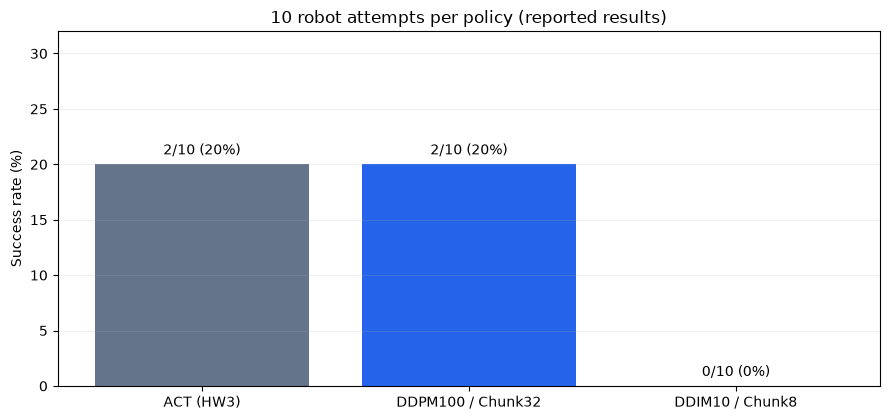

비교 제한: ACT는 과제3 재사용, DDPM은 30s/Chunk32/no-limit, DDIM은 20s/Chunk8/max_relative_target=2.0


In [32]:
# 기록된 정규 평가 성공률 시각화 — 회차별 DDPM 성공을 임의로 배정하지 않음
import matplotlib.pyplot as plt
fig,ax=plt.subplots(figsize=(9,4.3))
labels=["ACT (HW3)","DDPM100 / Chunk32", "DDIM10 / Chunk8"]
rates=[20,20,0]
bars=ax.bar(labels,rates, color=["#64748b","#2563eb","#14b8a6"])
ax.set_ylim(0,32); ax.set_ylabel("Success rate (%)");ax.set_title("10 robot attempts per policy (reported results)")
ax.grid(axis="y",alpha=.2)
for bar,score in zip(bars,[2,2,0]):
 ax.text(bar.get_x()+bar.get_width()/2,bar.get_height()+.6,f"{score}/10 ({score*10}%)",ha="center",va="bottom",fontsize=10)
plt.tight_layout();plt.show()
print("비교 제한: ACT는 과제3 재사용, DDPM은 30s/Chunk32/no-limit, DDIM은 20s/Chunk8/max_relative_target=2.0")


### 3-4. 물체 위치 변경에 대한 반응성 실험

원본 노트북 양식은 DDPM과 DDIM10에서 물체를 약 5cm 옮기고 다시 물체를 따라가는지를 각 3회 관찰하도록 요구한다. **이 별도 6회 실험 결과는 현재 확보되지 않았다.** 작업 성공률 10회 결과와 혼동하거나 반응성 성적을 성공/실패로 채우지 않는다.

오프라인 평가에서는 같은 관측 시연 프레임을 정책 입력으로 사용했으므로, **반응성(움직이는 물체를 새로 따라가는지)**을 직접 증명할 수 없다. 이 측정은 실시간 재관측, 새 행동 청크 생성 시간, 실제 모터 명령의 실행 주기를 모두 포함해야 한다.


In [33]:
reactivity={
 "dp":[{"trial":i,"followed":None,"note":"미측정: 물체 5cm 이동 실험 기록 없음"} for i in range(1,4)],
 "dp_ddim10":[{"trial":i,"followed":None,"note":"미측정: 물체 5cm 이동 실험 기록 없음"} for i in range(1,4)],
}
react_df=pd.concat([pd.DataFrame(reactivity[k]).assign(condition=LABELS[k]) for k in ["dp","dp_ddim10"]],ignore_index=True)
display(react_df)
print("반응성은 6회 중 0회 기록 확보. '미측정'은 실패와 다름.")


,trial,followed,note,condition
0,1,None,미측정: 물체 5cm 이동 실험 기록 없음,Diffusion DDPM100 (Chunk32)
1,2,None,미측정: 물체 5cm 이동 실험 기록 없음,Diffusion DDPM100 (Chunk32)
2,3,None,미측정: 물체 5cm 이동 실험 기록 없음,Diffusion DDPM100 (Chunk32)
3,1,None,미측정: 물체 5cm 이동 실험 기록 없음,Diffusion DDIM10 (Chunk8)
4,2,None,미측정: 물체 5cm 이동 실험 기록 없음,Diffusion DDIM10 (Chunk8)
5,3,None,미측정: 물체 5cm 이동 실험 기록 없음,Diffusion DDIM10 (Chunk8)


반응성은 6회 중 0회 기록 확보. '미측정'은 실패와 다름.


### 3-5. 녹화 데이터와 대표 GIF
### ACT Chunk100 실험 장면
![ACT 실험](images/hw4_act.png)

### DDPM100 실험 장면 — 2/10 성공
![DDPM100 실험](images/hw4_dp.png)

### DDIM10 실험 장면 — 0/10 성공
![DDIM10 실험](images/hw4_dp_ddim10.png)



In [34]:
# 로컬 PC의 실제 평가 녹화를 이용해 GIF 추출(선택) — 모터 연결 없음, 원본 MP4 변경 없음
from pathlib import Path
GIFS={"act":"hw4_act.gif", "dp":"hw4_dp.gif", "dp_ddim10":"hw4_dp_ddim10.gif"}
VIDEO_ROOTS={
 "dp":Path("C:/lerobot_data/rollout_ddpm100_chunk32_final_nolimit_20261122"),
 "dp_ddim10":Path("C:/lerobot_data/rollout_dp_ddim10_final_assignment4"),
}
OUT=Path("assignments/images") if Path("assignments").exists() else Path("images")
OUT.mkdir(parents=True,exist_ok=True)
for key,filename in GIFS.items():
 dest=OUT/filename
 if dest.exists(): print(f"[{key}] GIF 있음: {dest}"); continue
 root=VIDEO_ROOTS.get(key)
 if not root or not root.exists(): print(f"[{key}] 원본 MP4 미확인 — 나중에 실제 녹화가 있을 때 추출"); continue
 videos=sorted(root.rglob("*.mp4"))
 if not videos: print(f"[{key}] 녹화 MP4 없음: {root}"); continue
 # 실제 녹화가 있는 경우에만 OpenCV+Pillow로 4초 내외의 GIF를 만듦.
 try:
  import cv2
  from PIL import Image
  cap=cv2.VideoCapture(str(videos[0])); frames=[]; count=0
  fps=cap.get(cv2.CAP_PROP_FPS) or 15
  stride=max(1,round(fps/5))
  while cap.isOpened() and len(frames)<20:
   ok,frame=cap.read()
   if not ok: break
   if count%stride==0:
    frame=cv2.cvtColor(cv2.resize(frame,(320,240)),cv2.COLOR_BGR2RGB)
    frames.append(Image.fromarray(frame))
   count+=1
  cap.release()
  if frames:
   frames[0].save(dest,save_all=True,append_images=frames[1:],duration=200,loop=0,optimize=True)
   print(f"[{key}] 실제 녹화로 GIF 생성: {dest} ({len(frames)} frames, source={videos[0]})")
  else: print(f"[{key}] 영상 프레임 읽기 실패: {videos[0]}")
 except ImportError: print(f"[{key}] GIF 추출용 cv2 또는 Pillow 미설치 — 원본 MP4는 그대로 있음")
# ACT는 실제 과제3 영상 위치를 직접 지정해야 함.


[act] 원본 MP4 미확인 — 나중에 실제 녹화가 있을 때 추출
[dp] 실제 녹화로 GIF 생성: images\hw4_dp.gif (20 frames, source=C:\lerobot_data\rollout_ddpm100_chunk32_final_nolimit_20261122\videos\observation.images.cam0\chunk-000\file-000.mp4)
[dp_ddim10] 실제 녹화로 GIF 생성: images\hw4_dp_ddim10.gif (20 frames, source=C:\lerobot_data\rollout_dp_ddim10_final_assignment4\videos\observation.images.cam0\chunk-000\file-000.mp4)


## 4. 고찰 — 5문항

### 4-1. 가설 검증
과제 3의 ACT chunk100은 10회 중 2회 성공(20%)하였고, 2026-11-22 과제 4의 DDPM100 chunk32도 10회 중 2회 성공(20%)하였으며 DDIM10 chunk8은 10회 모두 실패(0%)하였다. 성공 횟수만 보면 ACT와 DDPM100이 같지만, ACT는 과제 3 결과를 재사용하였고 Diffusion 두 정책은 시간·청크·이동 제한 조건이 달랐다. 따라서 사전에 예상한 정책 간 우열을 통제된 결과로 검증했다고 보기 어렵다. 다만 실제 과제에서 DDPM100이 두 차례 물체 이동에 성공했다는 점은 이 정책이 동작을 수행할 수 있음을 확인해 준다.

### 4-2. ACT와 Diffusion의 행동 특성
ACT는 한 번의 추론으로 행동 청크를 생성하는 반면, Diffusion Policy는 반복적인 denoising으로 행동 시퀀스를 샘플링한다. DDIM10 초기 파일럿에서는 상대 이동 제한 0.5 때문에 실제 관절이 거의 움직이지 않거나 떨리는 현상이 관찰되었으며, 제한 2.0 설정의 정규 10회 평가에서도 물체 놓기 성공이 없었다. DDPM100은 청크8 및 제한 2.0에서 덜컥거림/소폭 이동이 관찰됐지만, 청크32와 상대 제한을 제거한 시험에서는 사용자가 정상적인 움직임을 보고하였다. 다만 이러한 변화는 모델 정책 자체의 품질과 함께 **추론 속도·청크 길이·제어 제한**의 복합적인 결과이므로 ACT 대비 원천적인 움직임 우수성을 단정하지 않는다.

### 4-3. 추론 속도와 DDPM100·DDIM10 비교
동일한 가중치 및 `n_action_steps=8`로 오프라인 비교한 결과, DDPM100은 새 청크 추론에 평균 **1641.526ms**, DDIM10은 **175.150ms**가 걸려 DDIM10이 약 **9.37배** 빨랐다. 반면 청크 경계 목표 변화의 평균은 DDPM100 **18.355°**, DDIM10 **21.890°**, 전문가 행동과의 팔 관절 평균 절대오차는 각각 **8.177°**와 **9.555°**였다. 이 수치는 recorded demonstration을 입력한 **개방루프 추론** 결과로서 실로봇의 통신·카메라·모터 지연이나 성공률을 직접 설명하는 값은 아니다. 실제 10회 성적은 DDPM100 2/10, DDIM10 0/10이었지만, 정식 로봇 평가는 청크·시간·이동 제한이 달라 추론 속도만의 영향은 분리할 수 없다.

### 4-4. 반응성과 행동 청크 길이
15fps 기준 행동 청크 8은 약 0.53초, 청크 32는 약 2.13초, ACT 청크100은 약 6.67초의 행동 명령 길이에 해당한다. 청크가 짧으면 더 자주 새로운 카메라 관측과 행동 생성이 가능하지만, DDPM100처럼 추론 시간이 길면 새 청크가 생성되기까지 제어가 끊어질 수 있다. 반대로 긴 청크는 추론 빈도를 낮추지만 외부 물체 위치 변화에 대한 반응이 느려질 수 있다. 실제 물체를 5cm 옮기는 반응성 추가 6회 시험 결과는 확보하지 못했으므로 어느 모델이 변위에 더 민감하게 반응했다고 단정하지 않는다.

### 4-5. 현재 태스크에서 선택할 정책 및 개선 방향
현재 수집된 성공률만 보면 ACT와 DDPM100은 모두 20%로 같고 DDIM10은 0%였으므로, 이번 로봇 실습 환경에서는 실제 성공을 보인 DDPM100과 ACT를 우선 검토할 수 있다. 다만 DDPM100은 30초·청크32·제한 없음, DDIM10은 20초·청크8·이동 제한 2.0이어서 같은 기준으로 반복 실험하기 전까지 최종 우승 정책을 선택하는 것은 조심스럽다. 추가 개선 방향은 동일한 시작 자세·물체 위치·카메라 조건·평가 시간으로 재평가하고, 제어 제한 및 행동 청크가 실제 동작에 미치는 영향을 별도 실험으로 나누는 것이다. 과제에서 학습한 50K 모델의 최종 Loss **0.027872**는 학습 수렴의 참고 값이며 실제 성공률을 대신하지 못한다.


### 4-6. 실로봇 기록 근거와 한계 정리

| 기록 유형 | 획득 방법 | 이 보고서에서의 사용 |
|---|---|---|
| ACT 10회 중 성공 2회 | 과제 3 원본 노트북 기존 관찰값 | **과거 비교 기준**, 이번 실습과 동일 조건 보장은 없음 |
| DDPM100 10회 중 성공 2회 | 2026-11-22 사용자 현장 보고 | **정식 실험 총계**, 성공 회차 번호 미기록 |
| DDIM10 10회 중 성공 0회 | 2026-11-22 사용자 현장 보고 | **정식 실험 총계**, 제한 설정 포함 |
| DDPM100 vs DDIM10 추론 ms | Episode 0·7, 기록된 시연 관측 사용 | **오프라인 개방루프 속도 비교**, 실제 FPS로 오인 금지 |
| 부드러움/반응성 정량 점수 | 공식 반복 결과 미제공 | **정성 관찰만 서술**, 수치 미생성 |

실험 완료를 의미하는 콘솔 문구와 실제 작업 성공은 다르므로, 작업 성공 횟수는 사용자의 개별 관찰을 기준으로 분리하여 기록했다.